In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, LabelEncoder, label_binarize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


# **`1. Data Preparation:`**



**Load the dataset into your preferred data analysis environment (e.g., Python with libraries like Pandas and NumPy).**

In [61]:
file = 'heart_disease.xlsx'
xls = pd.ExcelFile(file)
print(xls.sheet_names)

['Description', 'Heart_disease']


In [62]:
df = pd.read_excel(file, sheet_name = 1)

In [63]:
df.shape

(908, 13)

Explanation:
---

Loaded the heart_disease.xlsx file. First, we checked the sheet names and found two sheets: Description and Heart_disease. Then we selected the actual dataset sheet (sheet_name=1) and loaded it into a DataFrame.

# **`2. Exploratory Data Analysis (EDA):`**

**Perform exploratory data analysis to understand the structure of the dataset.**



In [64]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0


In [65]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch',
       'exang', 'oldpeak', 'slope', 'thal', 'num'],
      dtype='object')

In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    object 
 2   cp        908 non-null    object 
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    bool   
 6   restecg   908 non-null    object 
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    object 
 11  thal      908 non-null    object 
 12  num       908 non-null    int64  
dtypes: bool(1), float64(1), int64(5), object(6)
memory usage: 86.1+ KB


In [67]:
#statisical summary
df.describe()

,age,trestbps,chol,thalch,oldpeak,num
count,908.000000,908.000000,908.000000,908.000000,846.000000,908.000000
mean,53.791850,133.430617,201.484581,135.957048,0.891253,1.008811
std,9.158031,20.401608,112.097949,26.804929,1.093875,1.144436
min,29.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.750000,120.000000,176.750000,118.000000,0.000000,0.000000
50%,54.000000,130.000000,224.000000,138.000000,0.500000,1.000000
75%,60.000000,144.000000,270.000000,156.000000,1.500000,2.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,4.000000


**Check for missing values, outliers, and inconsistencies in the data.**


In [68]:
#misssing values
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0
oldpeak,62


In [69]:
df.isnull().sum().sum()/len(df)*100

np.float64(6.828193832599119)

In [70]:
#as missing value percentage is more than 5, so we will replace those with median
df.fillna({'oldpeak': df.oldpeak.median()}, inplace = True)

In [71]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0
oldpeak,0


In [72]:
#duplicates
df.duplicated().sum()

np.int64(1)

In [73]:
#dropping duplicated row
df.drop_duplicates(inplace=True)

In [74]:
df.duplicated().sum()

np.int64(0)

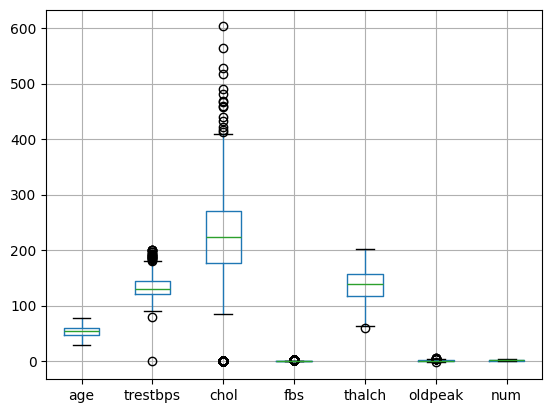

In [75]:
#outliers
df.boxplot()
plt.show()

In [76]:
#outlier capping
def outlier_capping(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(['int', 'float']).columns:
  outlier_capping(df, col)

**Visualize the distribution of features, including histograms, box plots, and correlation matrices.**

HISTOGRAMS:
---

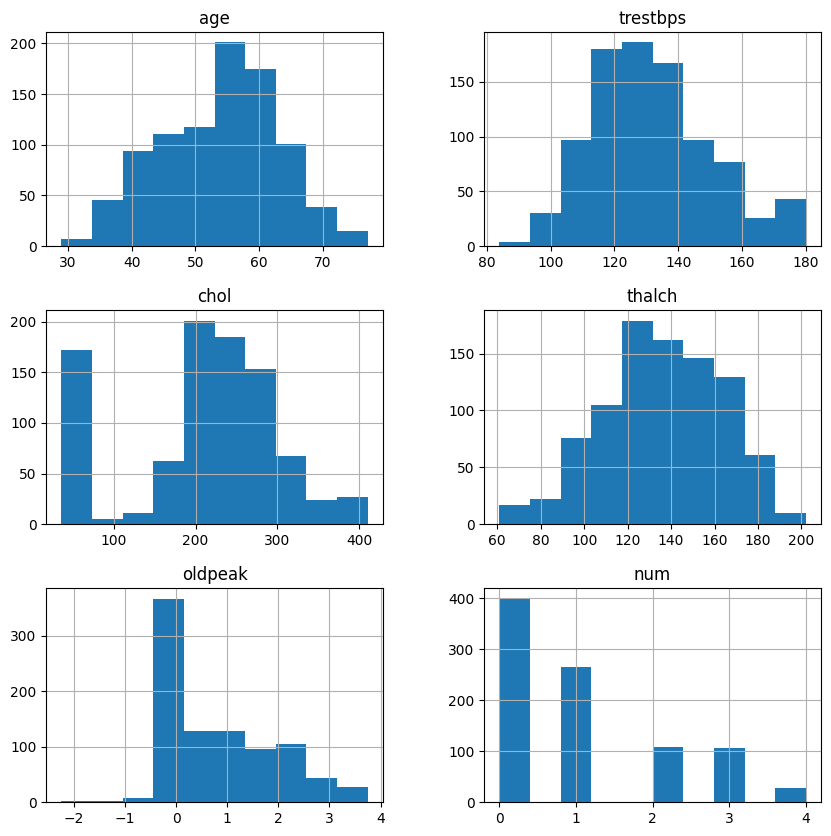

In [77]:
df.hist(figsize=(10, 10), bins = 10)
plt.show()

BOX PLOT
---

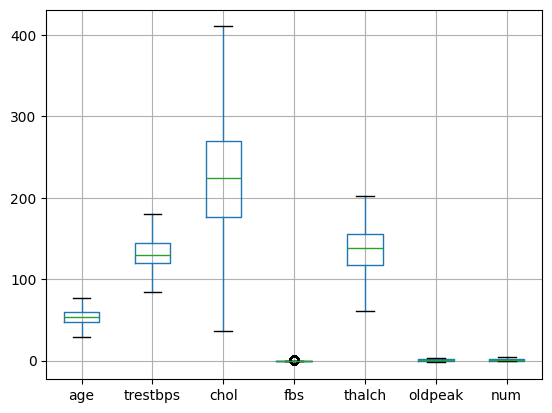

In [78]:
df.boxplot()
plt.show()

CORRELATION MATRICES:
---

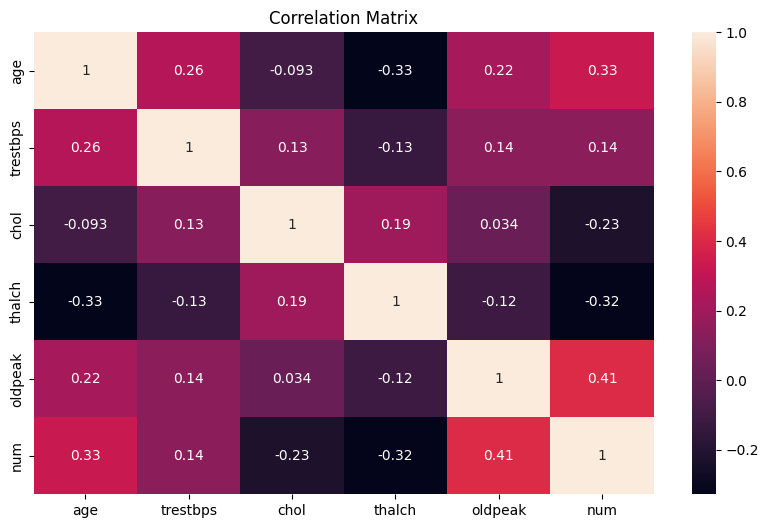

In [79]:
plt.figure(figsize=(10, 6))
corr = df.select_dtypes(include = ['int64', 'float64']).corr()

sns.heatmap( corr, annot = True)
plt.title('Correlation Matrix')
plt.show()

Explanation:
---

In this task, First I checked the dataset structure using shape, info and basic statistics. Then I checked for missing values and found that the oldpeak column had missing values more than 5%, so I handled them by replacing the missing values with the median of the oldpeak column. After that, I checked for duplicate rows and dropped them. Next, I treated and analysed outliers using boxplots. While observing the boxplot, I noticed outliers in the fbs column, but since fbs is a binary (0/1) feature, those points are valid values and do not affect the model, so I left it as it is. Finally, I visualized the dataset using histograms to understand feature distributions, boxplots to detect outliers, and a correlation matrix to study relationships between numerical features

# **`3. Feature Engineering:`**


**If necessary, perform feature engineering techniques such as encoding categorical variables, scaling numerical features, or handling missing values.**



Handling missing or irrelevant data
---

In [80]:
#handling irrelevant entries in exang column
df['exang'].unique()

array([False, True, 'FALSE', 'TURE'], dtype=object)

In [81]:
df['exang'] = df['exang'].replace({'FALSE': False, 'TURE': True})

In [82]:
df['exang'].unique()

array([False,  True])

Encoding Categorical variables
---

In [83]:
#categorical columns
cat_cols = df.select_dtypes(include = ['object']).columns
cat_cols

Index(['sex', 'cp', 'restecg', 'slope', 'thal'], dtype='object')

Here only slope is ordinal columns and remaining all nomial columns, so Label Encoder for ordinal columns and Set_dummies for nomial columns

In [84]:
#label encoder for ordinal column
le = LabelEncoder()

In [85]:
df['slope'] = le.fit_transform(df['slope'])

In [86]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,0,fixed defect,0
1,41,Male,atypical angina,135.0,203.0,False,normal,132.0,False,0.0,1,fixed defect,0
2,57,Male,asymptomatic,140.0,192.0,False,normal,148.0,False,0.4,1,fixed defect,0
3,52,Male,typical angina,118.0,186.0,False,lv hypertrophy,190.0,False,0.0,1,fixed defect,0
4,57,Male,asymptomatic,110.0,201.0,False,normal,126.0,True,1.5,1,fixed defect,0


In [87]:
#set dummies for nomial columns
df = pd.get_dummies(df, columns = ['sex', 'cp', 'restecg', 'thal'])

In [88]:
df.head()

,age,trestbps,chol,fbs,thalch,exang,oldpeak,slope,num,sex_Female,...,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,thal_fixed defect,thal_normal,thal_reversable defect
0,63,145.0,233.0,True,150.0,False,2.3,0,0,False,...,False,False,False,True,True,False,False,True,False,False
1,41,135.0,203.0,False,132.0,False,0.0,1,0,False,...,False,True,False,False,False,True,False,True,False,False
2,57,140.0,192.0,False,148.0,False,0.4,1,0,False,...,True,False,False,False,False,True,False,True,False,False
3,52,118.0,186.0,False,190.0,False,0.0,1,0,False,...,False,False,False,True,True,False,False,True,False,False
4,57,110.0,201.0,False,126.0,True,1.5,1,0,False,...,True,False,False,False,False,True,False,True,False,False


Scaling for numerical features
---

In [89]:
num_col = df.select_dtypes(include = ['int64', 'float64']).columns
num_col

Index(['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'slope', 'num'], dtype='object')

In [90]:
#here slope and num columns  will not be scaled, as  num is target and slope is already labeled
scale_col = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

In [91]:
std_sca = StandardScaler()
df[scale_col] = std_sca.fit_transform(df[scale_col])


In [92]:
df.head()

,age,trestbps,chol,fbs,thalch,exang,oldpeak,slope,num,sex_Female,...,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,thal_fixed defect,thal_normal,thal_reversable defect
0,1.006097,0.608289,0.265386,True,0.523305,False,1.409890,0,0,False,...,False,False,False,True,True,False,False,True,False,False
1,-1.396447,0.089952,-0.043590,False,-0.148458,False,-0.835450,1,0,False,...,False,True,False,False,False,True,False,True,False,False
2,0.350858,0.349120,-0.156881,False,0.448665,False,-0.444956,1,0,False,...,True,False,False,False,False,True,False,True,False,False
3,-0.195175,-0.791221,-0.218677,False,2.016110,False,-0.835450,1,0,False,...,False,False,False,True,True,False,False,True,False,False
4,0.350858,-1.205891,-0.064188,False,-0.372378,True,0.628902,1,0,False,...,True,False,False,False,False,True,False,True,False,False


Explanation:
---

In Feature Engineering to make the dataset ready for model training. First, the exang column contained inconsistent values like FALSE and TURE along with True/False, I cleaned it by replacing them with proper boolean values.  After that, I identified the categorical and numerical columns. Next, I encoded categorical variables by treating slope as an ordinal column and applying Label Encoding, and for the remaining nominal columns, applied set_dummies(). Finally, I scaled only the continuous numerical columns (age, trestbps, chol, thalch, oldpeak) using StandardScaler, while not scaling the binary and encoded categorical features. This completed feature engineering and made the dataset fully numerical and suitable for Decision Tree classification.

# **`4. Decision Tree Classification:`**


In [93]:
target = df[['num']]
features = df.drop(columns = ['num'])

**Split the dataset into training and testing sets (e.g., using an 80-20 split).**


In [94]:
x_train, x_test, y_train, y_test = train_test_split(features, target, train_size = 0.8, random_state = 50, stratify=target)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(725, 20)
(182, 20)
(725, 1)
(182, 1)


**Implement a Decision Tree Classification model using a library like scikit-learn.**


In [95]:
dec_tree = DecisionTreeClassifier(criterion = 'gini', splitter = 'best', max_depth = 3)
dec_tree.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3)

**Train the model on the training set and evaluate its performance on the testing set using appropriate evaluation metrics (e.g., accuracy, precision, recall, F1-score, ROC-AUC).**


In [96]:
#training the model
y_pred = dec_tree.predict(x_test)

In [97]:
#Evaluating its performance

print("Accuaracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1-score:", f1_score(y_test, y_pred, average='weighted'))


Accuaracy: 0.554945054945055
Precision: 0.4583419597982706
Recall: 0.554945054945055
F1-score: 0.4865842686338958


In [98]:
#convert y_test to 1D
y_true = y_test.values.ravel()
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3, 4])
y_prob = dec_tree.predict_proba(x_test)

In [99]:
roc_auc = roc_auc_score(y_true_bin, y_prob, multi_class='ovr', average='weighted')
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7517976153115125


Explanation:
---

 First, we separated the dataset into features and target and then split the data into training and testing sets using an 80–20 split. After that, we implemented a DecisionTreeClassifier using the Gini criterion and trained it using the training data. Finally, we tested the model using the test dataset and evaluated its performance using metrics like Accuracy, Precision, Recall, F1-score, and ROC-AUC. Since our target is multi-class (0,1,2,3,4), we used average=‘weighted’ for Precision, Recall and F1-score so that the result considers the class imbalance (classes with more samples get more weight). For ROC-AUC, because it is originally designed for binary classification, we calculated it using multi_class=‘ovr’ (One-vs-Rest) which compares each class against all remaining classes and gives an overall ROC-AUC score for multi-class classification.

# **`5. Hyperparameter Tuning:`**


**Perform hyperparameter tuning to optimize the Decision Tree model. Experiment with different hyperparameters such as maximum depth, minimum samples split, and criterion.**


Different maximum depth:
---

In [100]:
depth_values = [2, 3, 4, 5, 6]

for d in depth_values:
  model = DecisionTreeClassifier(max_depth = d)
  model.fit(x_train, y_train)

  y_pred = model.predict(x_test)
  acc = accuracy_score(y_test, y_pred)

  print(f"Accuracy for depth {d}: {acc}")


Accuracy for depth 2: 0.5274725274725275
Accuracy for depth 3: 0.554945054945055
Accuracy for depth 4: 0.5439560439560439
Accuracy for depth 5: 0.5054945054945055
Accuracy for depth 6: 0.5


Different sample splits:
---


In [101]:
split_values = [2, 5, 7, 10, 25]

for s in split_values:
  model = DecisionTreeClassifier(min_samples_split = s)
  model.fit(x_train, y_train)

  y_pred = model.predict(x_test)
  acc = accuracy_score(y_test, y_pred)

  print(f"Accuracy for model with sample splits {s}: {acc}")

Accuracy for model with sample splits 2: 0.47802197802197804
Accuracy for model with sample splits 5: 0.47802197802197804
Accuracy for model with sample splits 7: 0.4945054945054945
Accuracy for model with sample splits 10: 0.47802197802197804
Accuracy for model with sample splits 25: 0.4835164835164835


Different criterion:
---

In [102]:
criteria = ['gini', 'entropy']

for c in criteria:
  model = DecisionTreeClassifier(criterion = c)
  model.fit(x_train, y_train)

  y_pred = model.predict(x_test)
  acc = accuracy_score(y_test, y_pred)

  print(f"Accuracy for model with criterion {c}: {acc}")

Accuracy for model with criterion gini: 0.43956043956043955
Accuracy for model with criterion entropy: 0.46703296703296704


Explanation:
---

In hyperparameter tuning, we experimented with different parameters to improve the model performance and reduce overfitting. We tested max_depth to limit how deep the tree grows, min_samples_split to control splitting of nodes, and criterion (gini/entropy) to check the best splitting method. Based on the results, we selected the best combination of parameters that gave the highest accuracy on the test set i.e, maximum depth is 3, minimum sample splits is 25 and criterion is gini.

# **`6. Model Evaluation and Analysis:`**


**Analyse the performance of the Decision Tree model using the evaluation metrics obtained.**

I evaluated the Decision Tree model using metrics like accuracy, precision, recall, F1-score and ROC-AUC.
Since my target is multi-class, I used average = ‘weighted’ for precision/recall/F1 so that each class contribution is counted based on its number of samples (handles imbalance).
For ROC-AUC in multi-class, I used OVR (One-vs-Rest) method, which calculates AUC for each class against the remaining classes and then gives the final score

**Visualize the decision tree structure to understand the rules learned by the model and identify important features**

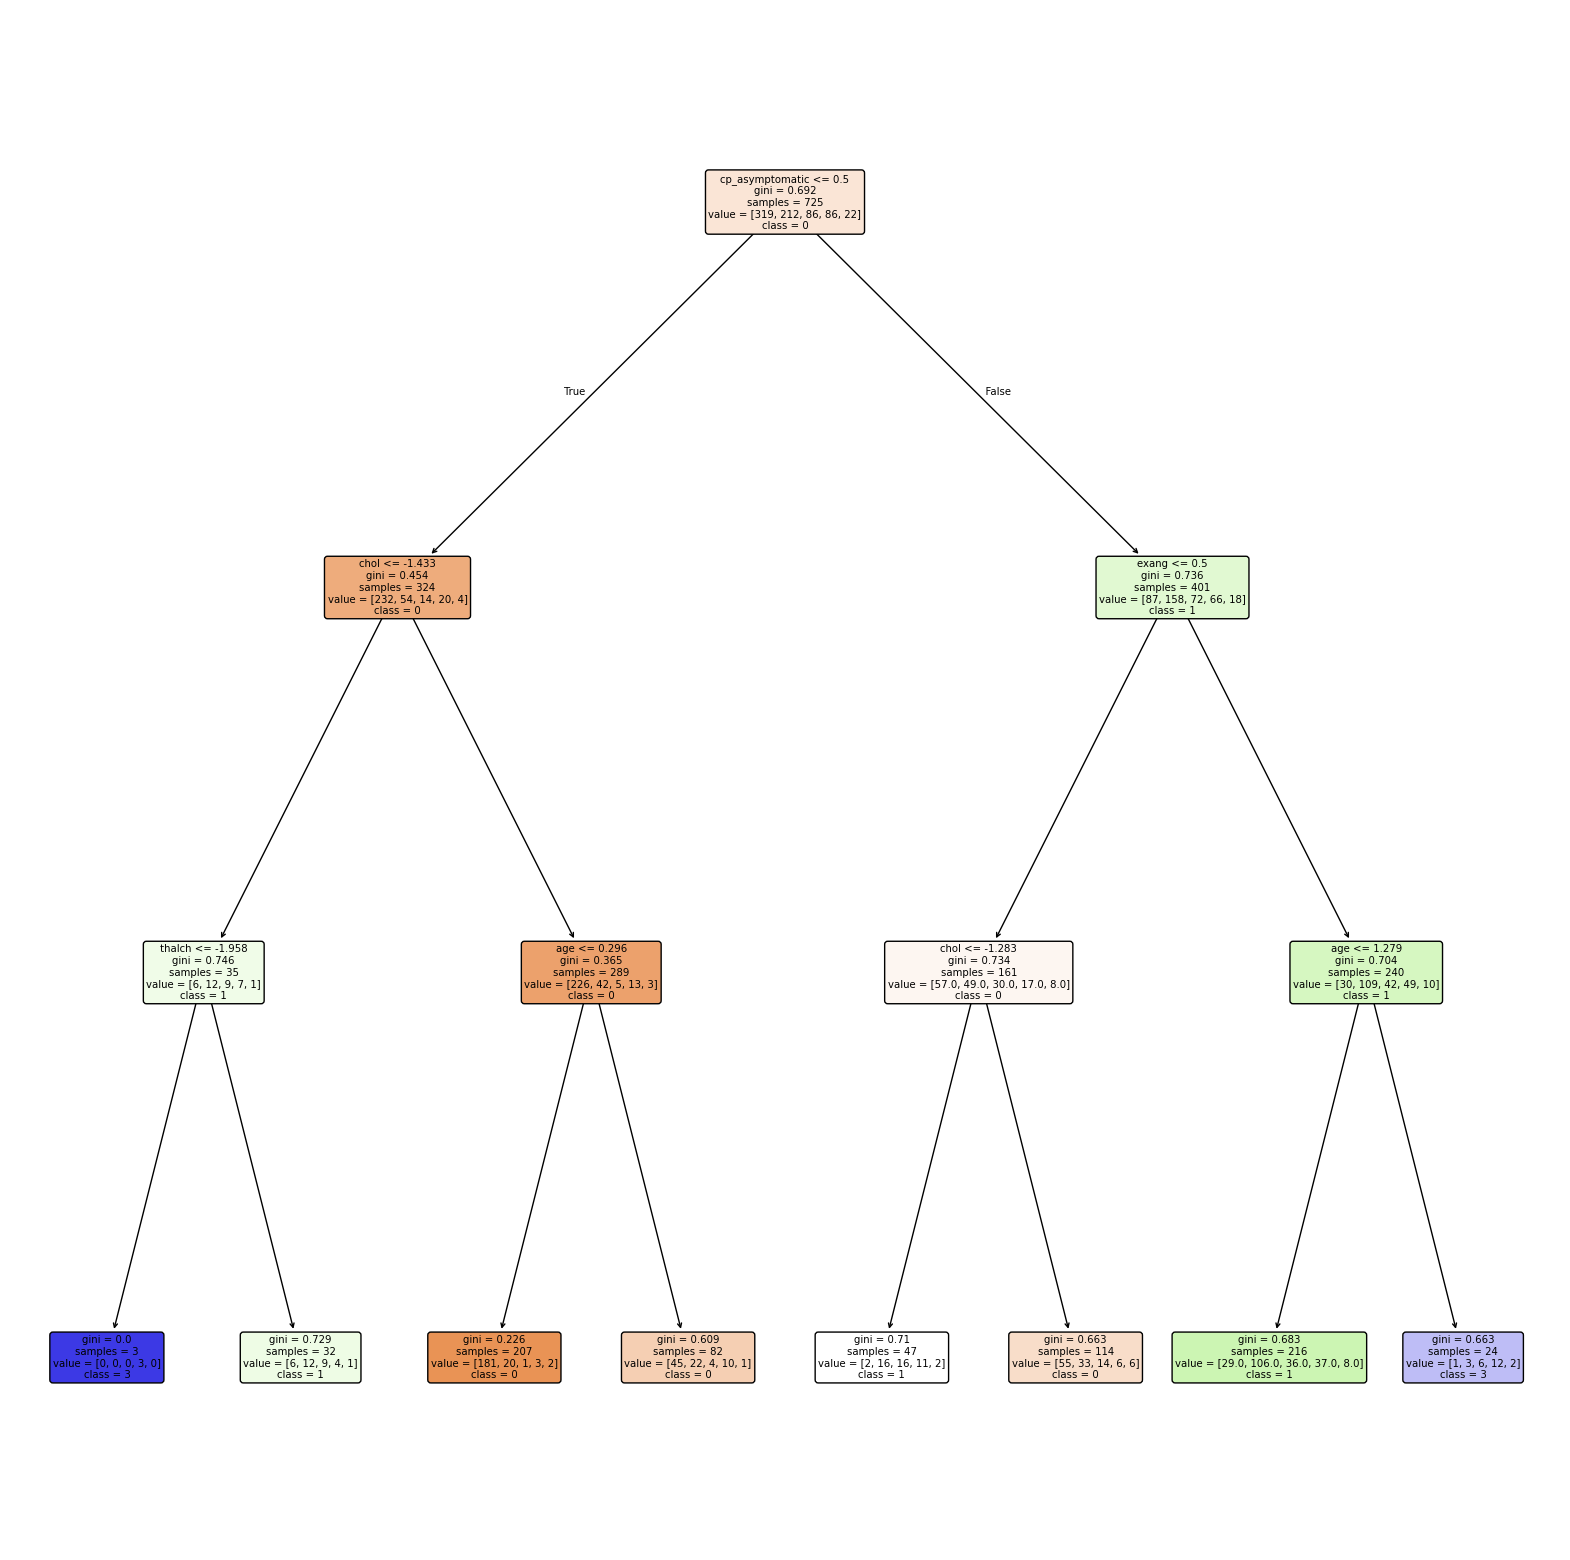

In [103]:
plt.figure(figsize=(20, 20))
plot_tree(dec_tree, filled=True, rounded = True, feature_names=list(features), class_names= [str(i) for i in sorted(df['num'].unique())])
plt.show();

Finally, we visualized the Decision Tree structure using plot_tree() to clearly understand the decision rules formed by the model and to interpret how the model is splitting features to predict the output. Since the target classes are numeric (0–4), we used str() inside class_names to convert them into string format so that the class labels are displayed correctly in the tree visualization.